In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Test.csv")

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (2627, 11)


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,458989,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6,B
1,458994,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6,A
2,458996,Female,Yes,69,No,NaN,0.0,Low,1.0,Cat_6,A
3,459000,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6,B
4,459001,Female,No,19,No,Marketing,NaN,Low,4.0,Cat_6,A


<class 'pandas.DataFrame'>
RangeIndex: 2627 entries, 0 to 2626
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               2627 non-null   int64  
 1   Gender           2627 non-null   str    
 2   Ever_Married     2577 non-null   str    
 3   Age              2627 non-null   int64  
 4   Graduated        2603 non-null   str    
 5   Profession       2589 non-null   str    
 6   Work_Experience  2358 non-null   float64
 7   Spending_Score   2627 non-null   str    
 8   Family_Size      2514 non-null   float64
 9   Var_1            2595 non-null   str    
 10  Segmentation     2627 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 225.9 KB


In [2]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

# Fill missing categorical values with the mode
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    if col != "Segmentation":
        df[col] = df[col].fillna(df[col].mode()[0])

# Fill missing numerical values with the median
numeric_cols = ["Work_Experience", "Family_Size"]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

print("Remaining missing values:", df.isnull().sum().sum())

ID                   0
Gender               0
Ever_Married        50
Age                  0
Graduated           24
Profession          38
Work_Experience    269
Spending_Score       0
Family_Size        113
Var_1               32
Segmentation         0
dtype: int64
Duplicate rows: 0
Remaining missing values: 0


C:\Users\ATUL\AppData\Local\Temp\ipykernel_23288\2932958980.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


In [3]:
features = df[[
    "Age",
    "Work_Experience",
    "Family_Size",
    "Spending_Score"
]].copy()

features["Spending_Score"] = features["Spending_Score"].map({
    "Low": 0,
    "Average": 1,
    "High": 2
})

display(features.head())

,Age,Work_Experience,Family_Size,Spending_Score
0,36,0.0,1.0,0
1,37,8.0,4.0,1
2,69,0.0,1.0,0
3,59,11.0,2.0,2
4,19,1.0,4.0,0


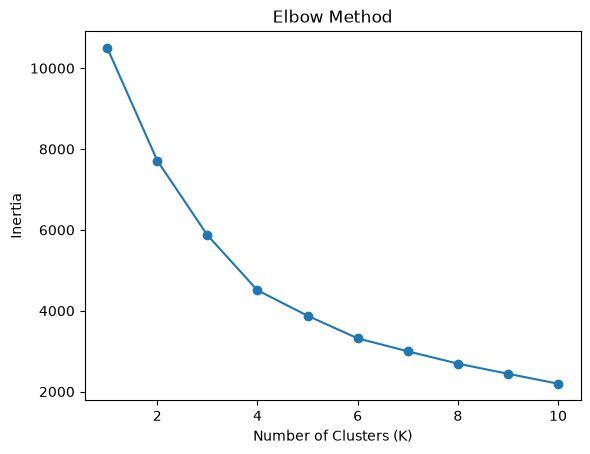

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.show()

In [10]:
average_age = df["Age"].mean()

average_work_experience = df["Work_Experience"].mean()

average_family_size = df["Family_Size"].mean()

most_common_spending_score = df["Spending_Score"].mode()[0]

spending_distribution = df["Spending_Score"].value_counts()

print("Average Customer Age:", round(average_age, 2))
print("Average Work Experience:", round(average_work_experience, 2))
print("Average Family Size:", round(average_family_size, 2))
print("Most Common Spending Score:", most_common_spending_score)

print("\nCustomer Spending Score Distribution:")
display(spending_distribution)

Average Customer Age: 43.65
Average Work Experience: 2.39
Average Family Size: 2.79
Most Common Spending Score: Low

Customer Spending Score Distribution:


Spending_Score
Low        1616
Average     625
High        386
Name: count, dtype: int64

### Descriptive Statistics — Observations

Descriptive statistics summarize the characteristics of customers in the dataset. Average age, work experience, and family size help describe the customer base. The spending score distribution shows how customers are classified as Low, Average, or High spenders.

Average purchase value, purchase frequency, and customer lifetime value cannot be calculated directly because the dataset does not include transaction amounts, order IDs, or purchase dates. Therefore, the available customer characteristics and spending scores will be used for the clustering analysis.

In [11]:
features = df[[
    "Age",
    "Work_Experience",
    "Family_Size"
]].copy()

print("Selected Features:")
display(features.head())

print("\nFeature Names:")
print(features.columns.tolist())

Selected Features:


,Age,Work_Experience,Family_Size
0,36,0.0,1.0
1,37,8.0,4.0
2,69,0.0,1.0
3,59,11.0,2.0
4,19,1.0,4.0



Feature Names:
['Age', 'Work_Experience', 'Family_Size']


### Feature Selection — Observations

Three numerical features, Age, Work Experience, and Family Size, were selected for customer segmentation. These features help identify groups of customers with similar characteristics. Since the dataset does not contain transaction history or purchase amounts, traditional RFM analysis cannot be performed. The selected features will be standardized before applying the K-Means clustering algorithm.